__**Enoncé SAE 1.02 4.2 : partie mathématique**__

Cette partie s’intéresse à la complexité temporelle des algorithmes implémentés au moyen de l’exploitation
des fichiers CSV générés dans la partie informatique. Pour ce faire il faudra écrire un notebook en python (.ipynb)
dans lequel chaque fichier CSV sera représenté par un graphe à l’aide de la bibliothèque matplotlib.
Pour utiliser un fichier CSV en python on pourra utiliser le squelette suivant :

In [12]:
fichier = open("nom_fichier.csv", 'r')
# Ouvre le fichier demandé
donnees = fichier.readlines()
# donnees reçoit les lignes du fichier sous forme de liste, donnees[0] est la première ligne ...
for ligne in donnees:
    valeurs = ligne.split(";")
    # Découpe la chaîne de caractère correspondant à la ligne selon le caractère ";" et renvoie une liste.
    # Traiter les données : valeurs[0] correspond à la première colonne de la ligne considérée, valeurs[1] la seconde colonne et valeurs[2] la 3ème.


__Dans un premier temps__, afin de déterminer expérimentalement la complexité de chacun des algorithmes en fonction des API avec votre structure, il faudra comparer graphiquement chaque courbe avec les courbes des fonctions de références pour les classes algorithmiques. Il ne faudra pas oublier de donner vos conclusions en donnant pour chaque algorithme
à quelle classe de complexité il semble appartenir. Pour les algorithmes où il y a 3 données, on prendra comme valeur pour l’abscisse NBELEM + NBINS / 2.

On rappelle les différentes classes de complexité :
| Classe | Fonction de référence |
| :--- | :--- |
| Constant | x ↦ 1 |
| Logarithmique | x ↦ log(x) |
| Linéaire | x ↦ x |
| Quasi-linéaire | x ↦ xlog(x) |
| Quadratique | x ↦ $x^{2}$ |
| Cubique | x ↦ $x^{3}$ |
| Exponentiel | x ↦ $e^{x}$ |

__Dans un second temps__, on va essayer de déterminer de façon théorique la complexité des algorithmes programmés.

On rappelle rapidement l’heuristique pour évaluer la complexité temporelle d’un algorithme :

* Les affectations, les sommes et les produits sont en temps constant (O(1)).
* Les test conditionnels (if) sont assez rapides et prennent aussi un temps constant (O(1)).
* Les boucles for prennent n fois le temps pris par un tour de boucle.
* Les boucles while quant à elles sont plus dures à estimer, il faut encadrer le nombre de tours possibles et
prennent entre n et m fois le temps pris par un tour de boucle où n est le nombre minimum de tours de la
boucle while et m le nombre maximum de tours.
* Pour les algorithmes récursifs, on détermine la formule de récurrence de la complexité temporelle, de la forme
  T(n) = a × T (n / b) + f(n) où a représente le nombre d’appel récursif, n / b la taille du problème dans chaque appel récursif et f(n) la complexité sans les appels récursifs. Et on utilise le théorème maître, en
l’occurrence pour le tri fusion, cela donne O(n^(logb(a))*log(n)). (Il faudra remplacer a et b par leurs valeurs respectives.)

Inclure vos estimations dans le fichier notebook python.


__Dans un troisième et dernier temps__, utiliser les deux résultats précédents pour en déduire la complexité temporelle des méthode d’accès get et set de votre structure de données. On répondra à cette question également dans le fichier notebook python.

À la fin de la SAÉ, vous devez rendre sur Moodle le fichier notebook python contenant l’ensemble des 3 parties mathématiques du sujet.

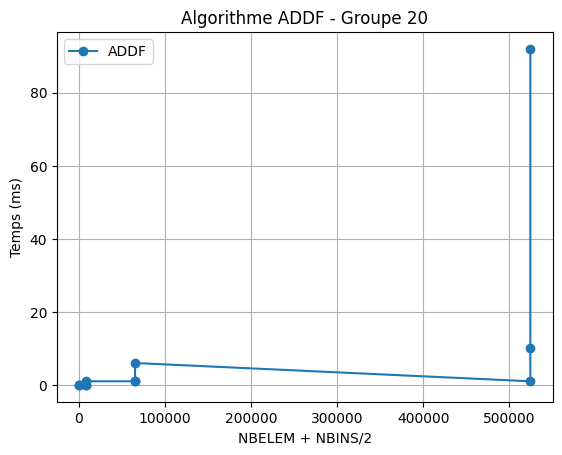

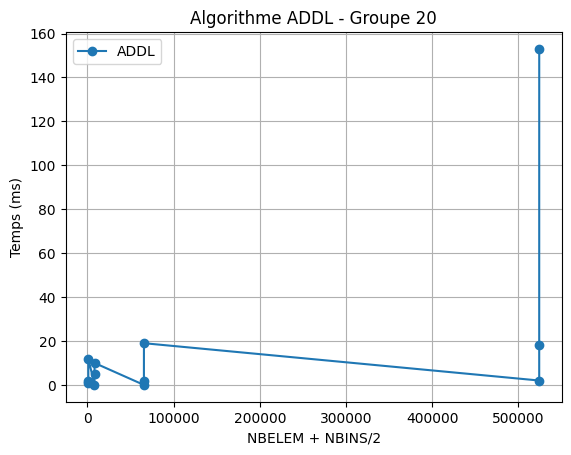

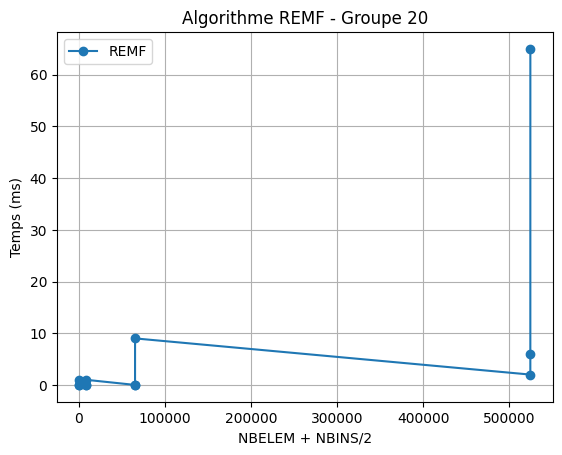

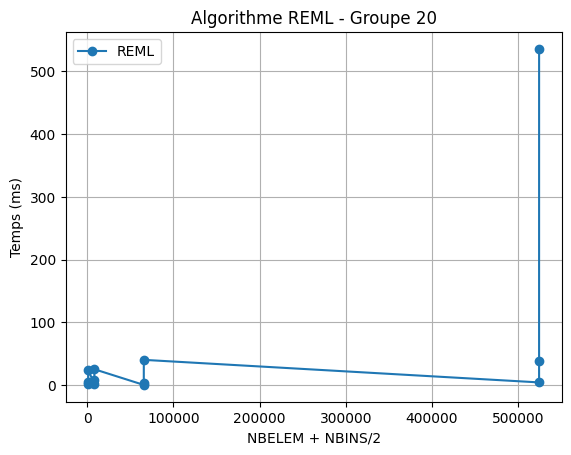

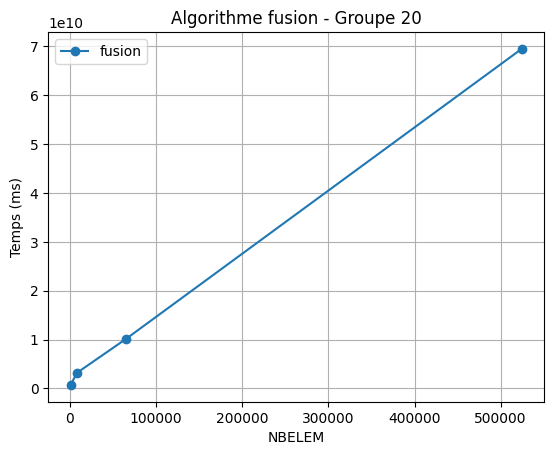

In [15]:
import matplotlib.pyplot as plt

# Liste des fichiers à traiter
fichiers = ['gp20-ADDF-ITER.csv', 'gp20-ADDL-ITER.csv', 
            'gp20-REMF-ITER.csv', 'gp20-REML-ITER.csv']

for nom_fichier in fichiers:
    # Extraire le nom de l'algo
    algo = nom_fichier.split('-')[1]  # ADDF, ADDL, REMF ou REML
    
    fichier = open(nom_fichier, 'r')
    # Ouvre le fichier demandé
    donnees = fichier.readlines()
    # donnees reçoit les lignes du fichier sous forme de liste,
    # donnees[0] est la première ligne ...
    
    # Initialiser les listes
    x = []
    y = []
    
    for ligne in donnees:
        valeurs = ligne.split(";")
        # Découpe la chaîne de caractères correspondant à la ligne selon le caractère ";" et renvoie une liste.
        # Traiter les données : valeurs[0] correspond à la première colonne de la ligne considérée, valeurs[1] la seconde colonne et valeurs[2] la 3ème.
        
        # Ignorer la première ligne d'en-tête
        if valeurs[0] != "NBELEM":
            nbelem = int(valeurs[0])
            nbins = int(valeurs[1])
            temps = float(valeurs[2])
            
            # Calculer l'abscisse
            x.append(nbelem + nbins / 2)
            y.append(temps)
    
    fichier.close()
    
    # Créer le graphique pour cet algorithme
    plt.plot(x, y, 'o-', label=algo)
    plt.xlabel('NBELEM + NBINS/2')
    plt.ylabel('Temps (ms)')
    plt.title(f'Algorithme {algo} - Groupe 20')
    plt.grid(True)
    plt.legend()
    plt.show()

x = []
y = []
fichier = open("gp20-Fusion-TAB.csv")
donnees = fichier.readlines()
for ligne in donnees:
    nbelem,temps = ligne.strip().split(";")
    if nbelem != "NBELEM":
        x.append(int(nbelem))
        y.append(int(temps))
fichier.close()
plt.plot(x, y, 'o-', label="fusion")
plt.xlabel('NBELEM')
plt.ylabel('Temps (ms)')
plt.title(f'Algorithme fusion - Groupe 20')
plt.grid(True)
plt.legend()
plt.show()
    

__Détermination de la complexité :__

__**Complexité d'ADDF:**__

    
* **Sur le graphique :** la complexité serait O($e^{x}$), en regardant le temps maximum de chaque NBELEM, on peut voir le temps augmenter de manière exponentielle. Même si cela n'est pas facile à lire sur le graphique.

* **D'après le code :** la complexité serait O(n²) en raison de la boucle for et du rewind(). En effet, la procédure addItem() est la constante mais répétée n fois. Et la procédure rewind() permet de revenir au début, donc elle dépend du nombre d'éléments du tableau. Donc la complexité est quadratique.


__**Complexité d'ADDL:**__
        
* **Sur le graphique :** la complexité serait O($e^{x}$) en regardant le temps maximum de chaque NBELEM, mais ce dernier semble varier plus qu'ADDL en vue des valeurs.

* **D'après le code :** la complexité serait O($e^{3}$) en raison de la boucle for, rewind() et de while. En effet, la procédure addItem() est la constante mais répétée n fois. La procédure rewind() permet de revenir au début, donc elle dépend du nombre d'éléments du tableau. Et la boucle while parcourt tous les éléments du tableau pour aller à la fin. Ainsi, la complexité serait cubique. 


__**Complexité de REMF:**__ 
    
* **Sur le graphique :** La complexité serait O($e^{x}$), en regardant le temps maximum de chaque NBELEM, on peut voir le temps augmenter de manière exponentielle. Même si cela n'est pas facile à lire sur le graphique.

* **D'après le code :** La complexité serait O(n²) en raison de la boucle for et du rewind(). En effet, la procédure addItem() et la condition sont constantes, mais répétées n fois. Et la procédure rewind() permet de revenir au début, donc elle dépend du nombre d'éléments du tableau. Donc la complexité est quadratique.


__**Complexité de REML:**__
        
* **Sur le graphique :** la complexité serait O($e^{x}$) en regardant le temps maximum de chaque NBELEM, mais ce dernier semble varier plus que REMF en vue des valeurs. Nous remarquons aussi que la procédure prend plus de temps que le ADDL.

* **D'après le code :** la complexité serait O($e^{3}$) en raison de la boucle for, rewind() et de while. En effet, la procédure addItem() est la constante mais répétée n fois. La procédure rewind() permet de revenir au début, donc elle dépend du nombre d'éléments du tableau. Et la boucle while parcourt tous les éléments du tableau pour aller à la fin. Ainsi, la complexité serait cubique. 


__**Complexité de Fusion:**__
    
* **Sur le graphique :** la complexité est quasi-linéaire. Il est quand-même important de la distinguer de la complexité linaire, mais la différence est fine.
    
* **D'après le code:** l'algorithme est récursif pour effectuer les différentes fusions. Pour calculer la récursivité, on peut découper en sous-tableaux n/2 puisque l'on fusionne deux tableaux et que la fusion des tableaux est linéaire. Donc cela fait 2T(n/2) + f(n). Ainsi, la complexité de la fusion est linéaire et le nombre de niveaux est log(n). La complexité finale est O(nlog(n)).

Enfin, nous devons, en fonction des résultat eu précédemment, déduire la complexité temporelle des méthode get et set de la structure de données. 

Pour commencer, la complexité de get est linaire, en fonction du nombre d'éléments et de l'argument passé en paramètre même si la durée d'exécution est rapide ce dernier peut monter très vite à mesure des éléments. 
Ensuite, la complexité de set est similaire à celle de get, même si elle prend deux arguments. La procédure parcourt de tableaux qu'avec arrivé à l'élément voulu et change la value. Elle demande, un peu plus de temps que get, mais cela est insignifiant.

Donc les complexités de ces algorithmes sont linaires soit O(n) et dépends du nombre d'éléments du tableau et de l'index. 